## Loading needed libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from statsmodels.tsa.stattools import adfuller, coint
from statsmodels.tsa.vector_ar.vecm import select_order, select_coint_rank

## Loading dataset

In [2]:
data = pd.read_csv('../data/raw/merged_df_new.csv', parse_dates=['Date'])
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2801 entries, 0 to 2800
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Date          2801 non-null   datetime64[ns]
 1   target        2801 non-null   float64       
 2   Oil_price     2801 non-null   float64       
 3   Gas_price     2801 non-null   float64       
 4   Nasdaq_price  2801 non-null   float64       
 5   Coal_price    2801 non-null   float64       
 6   stoxx_value   2801 non-null   float64       
dtypes: datetime64[ns](1), float64(6)
memory usage: 153.3 KB


## Configuration
Wszystkie parametry w jednym miejscu.

In [3]:
TARGET = "target"
cols = data.columns.drop("Date").to_list()          # wszystkie kolumny poza datą (razem z target)
regressors = [c for c in cols if c != TARGET]
print(cols)

# dodatkowe zestawy regresorów dla Engle'a-Grangera (oprócz pojedynczych zmiennych i par)
extra_sets = {
    "all_vars": regressors,
    "energy_only": [c for c in regressors if c != "Nasdaq_price"],
}

# liczba opóźnień VAR (p) dla testu Johansena - do testu idzie k_ar_diff = p - 1.
# Wpisz 'aic' / 'bic' / 'hqic' / 'fpe', żeby wziąć k_ar_diff wprost z select_order().
var_lags = {"raw": 1, "log": 7}

['target', 'Oil_price', 'Gas_price', 'Nasdaq_price', 'Coal_price', 'stoxx_value']


## Functions

In [ ]:
def apply_transform(df, cols, transform):
    """Zwraca kopię df z kolumnami `cols` w wersji 'raw' lub 'log'."""
    out = df.copy()
    if transform == "log":
        bad = [c for c in cols if (out[c] <= 0).any()]
        if bad:
            raise ValueError(f"Logarytm niemożliwy (wartości <= 0) w kolumnach: {bad}")
        out[cols] = np.log(out[cols])
    elif transform != "raw":
        raise ValueError("transform musi być 'raw' albo 'log'")
    return out


def plot_series(df, cols, kind="line", transform="raw", target="target",
                date_col="Date", figsize=None):
    """
    Jedna funkcja zamiast czterech pętli z wykresami.
    kind='line'    -> wykres każdej kolumny w czasie
    kind='scatter' -> target vs każda pozostała kolumna
    transform      -> 'raw' lub 'log'
    """
    if figsize is None:
        figsize = (8, 5) if kind == "line" else (5, 5)
    d = apply_transform(df, cols, transform)
    log = transform == "log"

    for col in cols:
        if kind == "scatter" and col == target:
            continue
        plt.figure(figsize=figsize)
        if kind == "line":
            plt.plot(d[date_col], d[col])
            plt.xlabel("Date")
            plt.ylabel(col)
            plt.title(f"log({col})" if log else col)
        elif kind == "scatter":
            plt.scatter(d[target], d[col])
            plt.xlabel("log(CO2 price)" if log else "CO2 price")
            plt.ylabel(f"log({col})" if log else col)
            plt.title(f"log(CO2 price) vs log({col})" if log else f"CO2 price vs {col}")
        else:
            raise ValueError("kind musi być 'line' albo 'scatter'")
        plt.show()


def run_analysis(
    df,
    cols,
    target="target",
    transforms=("raw", "log"),
    alpha_adf=0.01,
    alpha_coint=0.05,
    trends=("c", "ct", "ctt"),
    n_regressors=(1, 2),
    extra_sets=None,
    johansen=True,
    johansen_cols=None,
    var_lags=None,
    johansen_maxlags=10,
    johansen_det_order=0,
    johansen_signif=0.05,
    verbose=False,
):
    """
    Główna funkcja: ADF + Engle-Granger + Johansen dla każdej transformacji.

    Parametry
    ---------
    df            : DataFrame z kolumnami `cols` (bez wartości <= 0, jeśli 'log')
    cols          : lista kolumn (łącznie z target)
    trends        : trendy dla coint(): 'c', 'ct', 'ctt', 'n'
    n_regressors  : (1, 2) = target vs pojedyncze zmienne ORAZ vs pary zmiennych
    extra_sets    : dict {nazwa: [zmienne]} - dodatkowe zestawy regresorów,
                    np. {"all_vars": [...], "energy_only": [...]}
    johansen_cols : kolumny do testu Johansena (domyślnie wszystkie `cols`, z target)
    var_lags      : dict {transform: p}, p = liczba opóźnień VAR; do testu idzie
                    k_ar_diff = p - 1 (jak w oryginale). Wartość 'aic'/'bic'/'hqic'/'fpe'
                    bierze k_ar_diff wprost z select_order(). Brak klucza -> 'aic'.

    Zwraca
    ------
    dict z DataFrame'ami: {'adf', 'coint', 'johansen'}
    """
    regressors = [c for c in cols if c != target]
    extra_sets = extra_sets or {}
    var_lags = var_lags or {}
    johansen_cols = johansen_cols or list(cols)

    adf_rows, coint_rows, joh_rows = [], [], []

    for tf in transforms:
        d = apply_transform(df, cols, tf)   # log liczony raz na transformację

        # ---------- ADF ----------
        for col in cols:
            for kind, s in (("level", d[col]), ("diff", d[col].diff().dropna())):
                res = adfuller(s, result_object=True)
                adf_rows.append({
                    "transform": tf, "series": kind, "variable": col,
                    "adf_stat": res.statistic, "p_value": res.pvalue,
                    "stationary": res.pvalue < alpha_adf,
                })

        # ---------- Engle-Granger ----------
        specs = []
        for k in n_regressors:
            label = {1: "single", 2: "pair"}.get(k, f"{k}-set")
            specs += [(label, list(combo)) for combo in combinations(regressors, k)]
        specs += [(name, list(vars_)) for name, vars_ in extra_sets.items()]

        y = d[target]
        for group, combo in specs:
            for trend in trends:
                p = coint(y, d[combo], trend=trend)[1]
                coint_rows.append({
                    "transform": tf, "group": group, "trend": trend,
                    "regressors": " & ".join(combo),
                    "p_value": p, "cointegrated": p < alpha_coint,
                })
                if verbose:
                    print(f"EG | {tf} | {trend} | {group}: {combo} -> p={p:.4f}")

        # ---------- Johansen ----------
        if johansen:
            data_j = d[johansen_cols].dropna()
            lag_sel = select_order(data_j, maxlags=johansen_maxlags, deterministic="ci")

            p_var = var_lags.get(tf, "aic")
            if isinstance(p_var, str):
                k_ar_diff = int(lag_sel.selected_orders[p_var])
                lag_info = f"{p_var} (k_ar_diff={k_ar_diff})"
            else:
                k_ar_diff = p_var - 1
                lag_info = f"p={p_var} (k_ar_diff={k_ar_diff})"

            rank_test = select_coint_rank(
                data_j, det_order=johansen_det_order, k_ar_diff=k_ar_diff,
                method="trace", signif=johansen_signif,
            )
            for r0, (stat, cv) in enumerate(zip(rank_test.test_stats, rank_test.crit_vals)):
                joh_rows.append({
                    "transform": tf, "lags": lag_info, "H0: rank <=": r0,
                    "trace_stat": stat, "crit_value": cv, "reject_H0": stat > cv,
                    "selected_rank": rank_test.rank,
                })
            if verbose:
                print(lag_sel.summary())
                print(rank_test.summary())

    return {
        "adf": pd.DataFrame(adf_rows),
        "coint": pd.DataFrame(coint_rows),
        "johansen": pd.DataFrame(joh_rows),
    }


def integration_order(adf):
    """Zbiorcza klasyfikacja: I(0) / I(1) / wyższy rząd - na podstawie tabeli ADF."""
    piv = adf.pivot_table(index="variable", columns=["transform", "series"],
                          values="stationary", aggfunc="first")
    out = {}
    for tf in piv.columns.get_level_values("transform").unique():
        out[tf] = piv[tf].apply(
            lambda r: "I(0)" if r["level"] else ("I(1)" if r["diff"] else "I(2)+"), axis=1
        )
    return pd.DataFrame(out)


## Visualizations

### Raw time-series

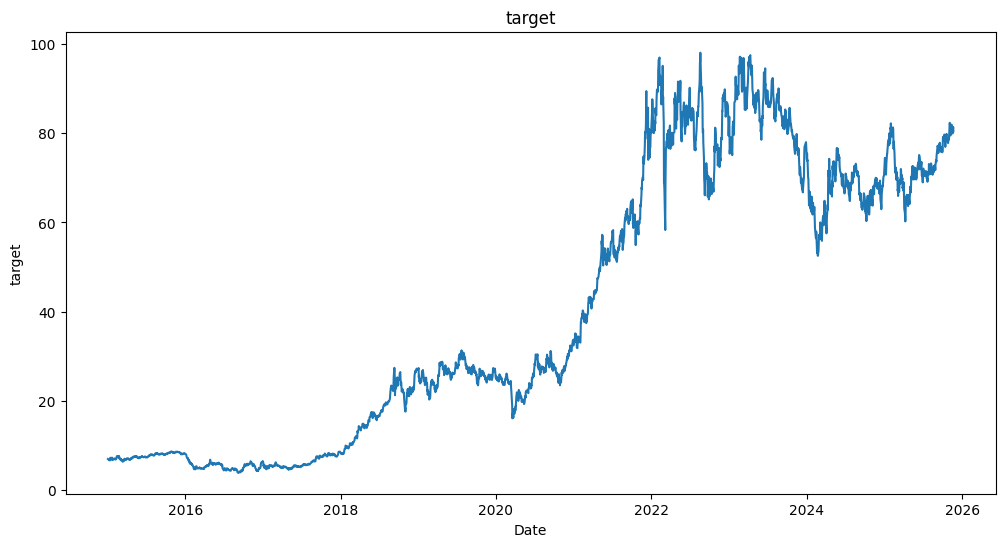

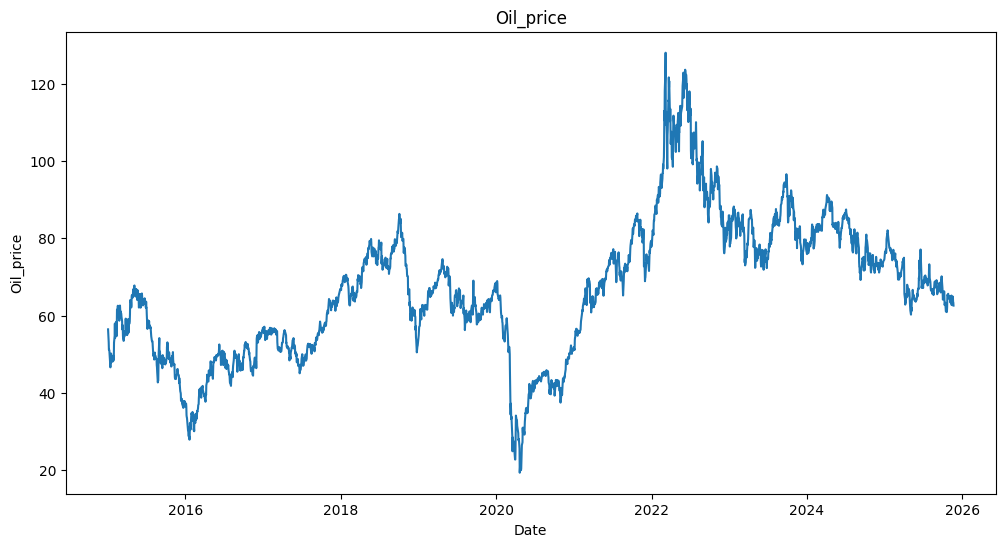

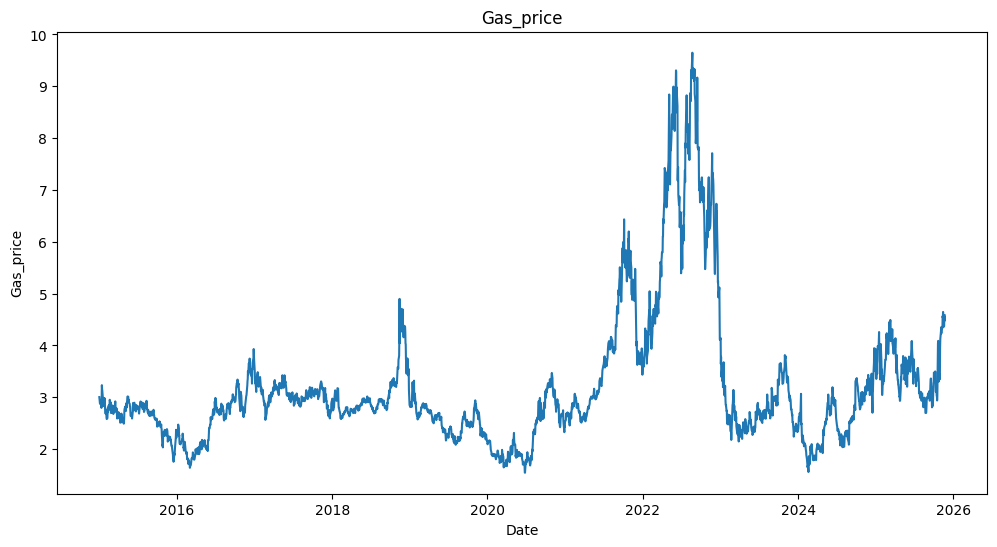

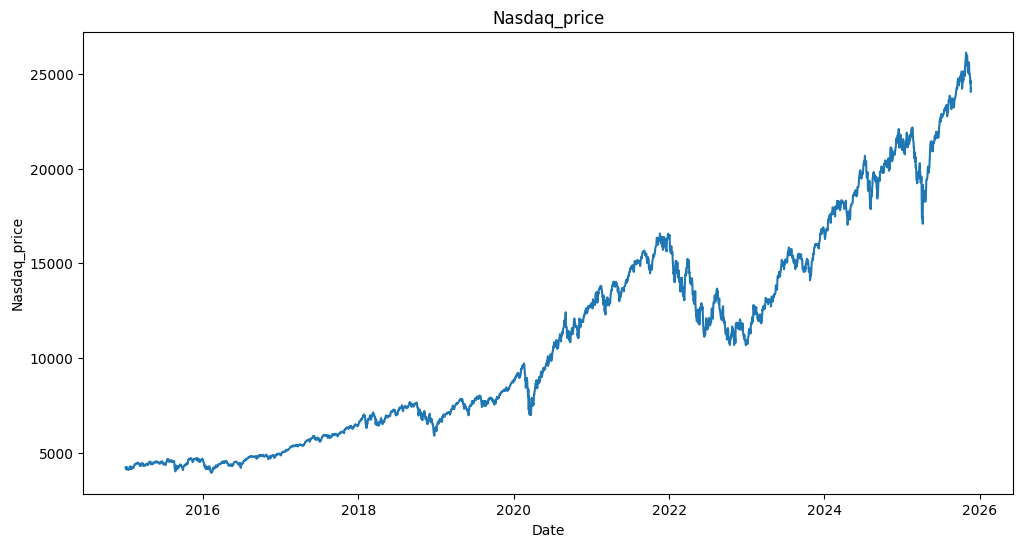

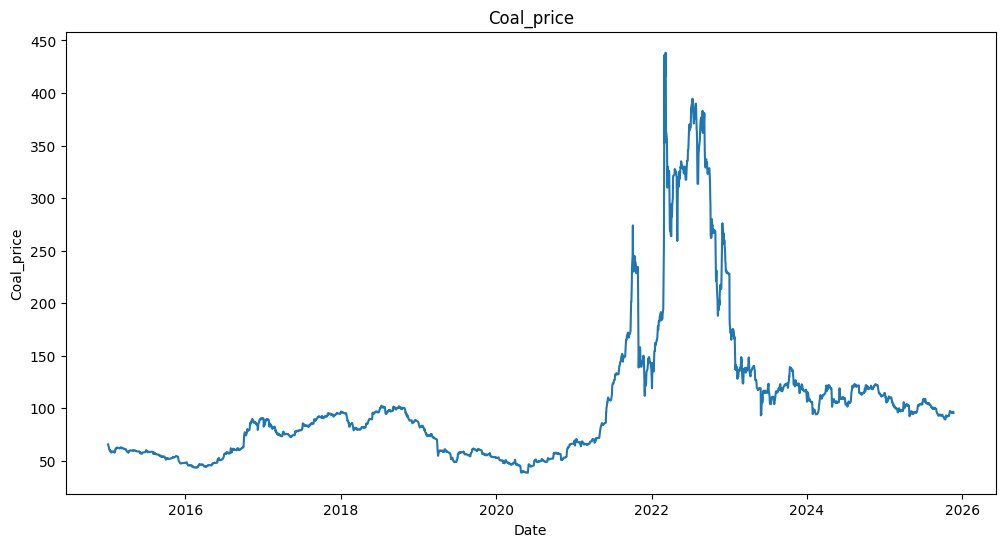

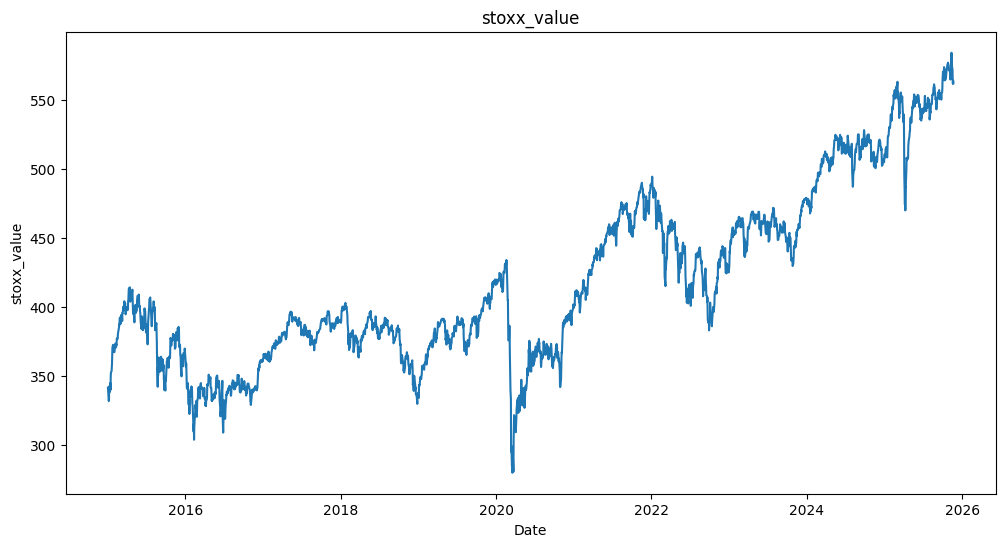

In [5]:
plot_series(data, cols, kind='line', transform='raw')

### Logged time series

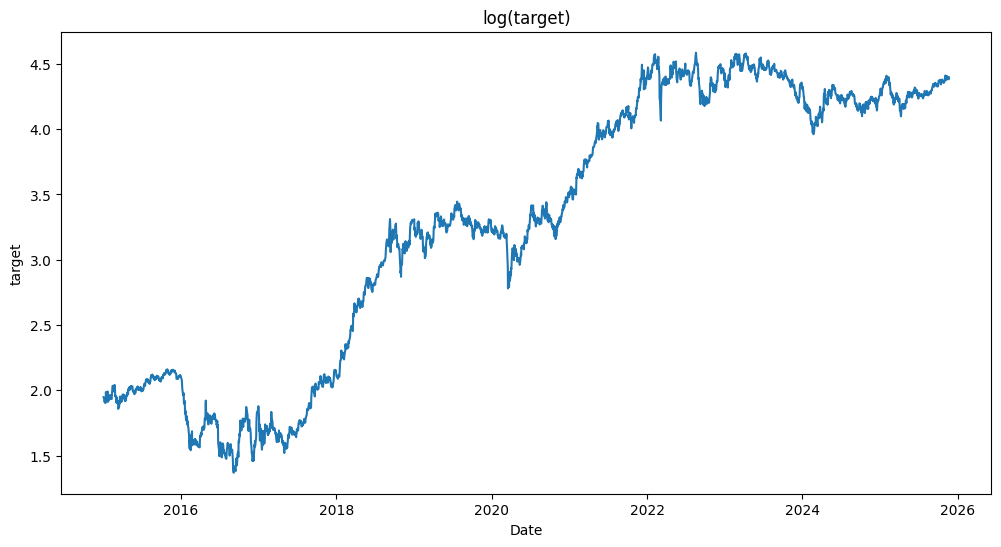

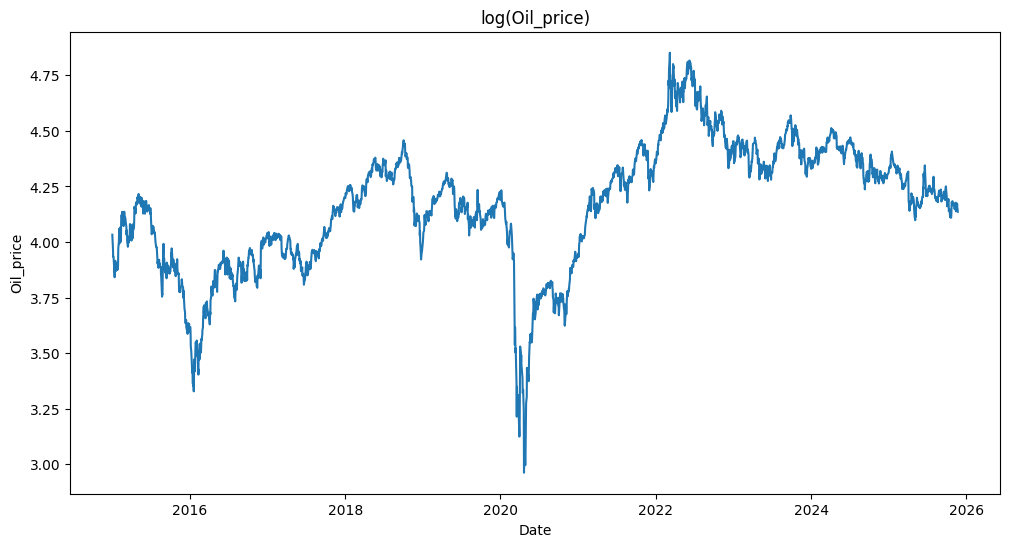

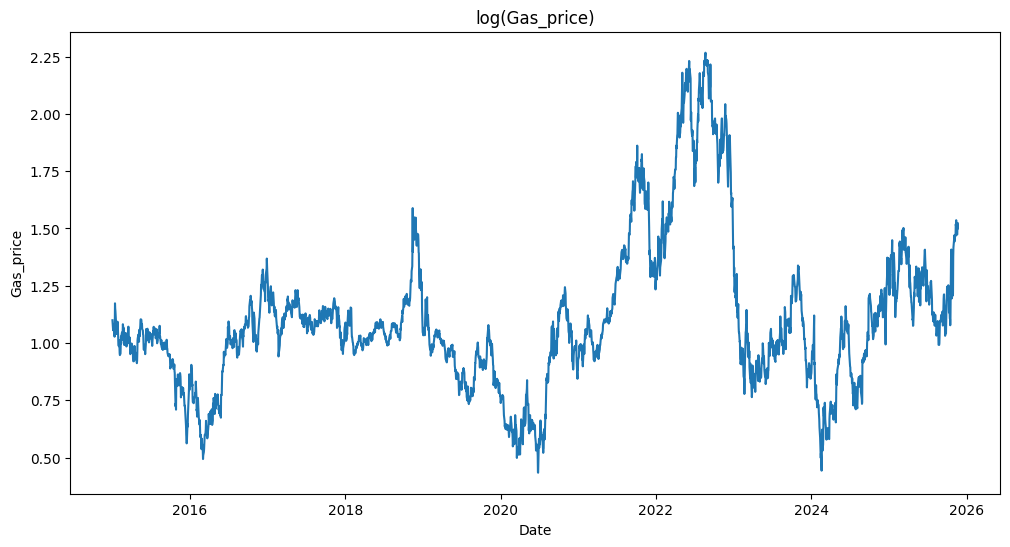

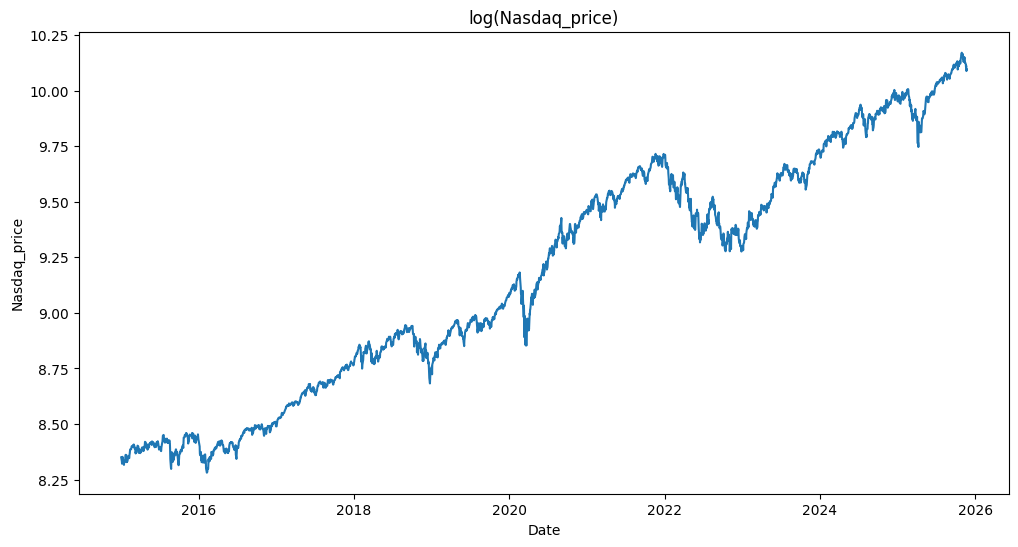

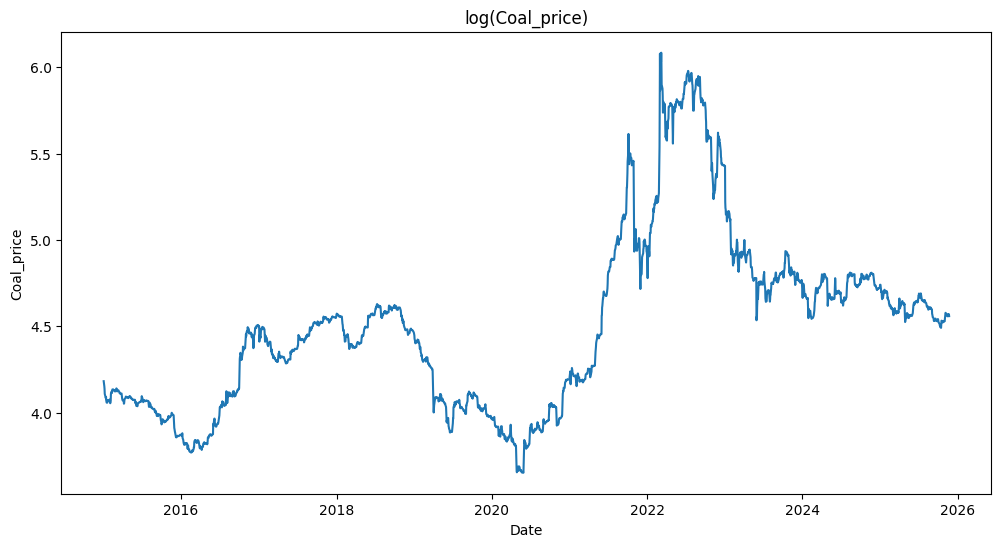

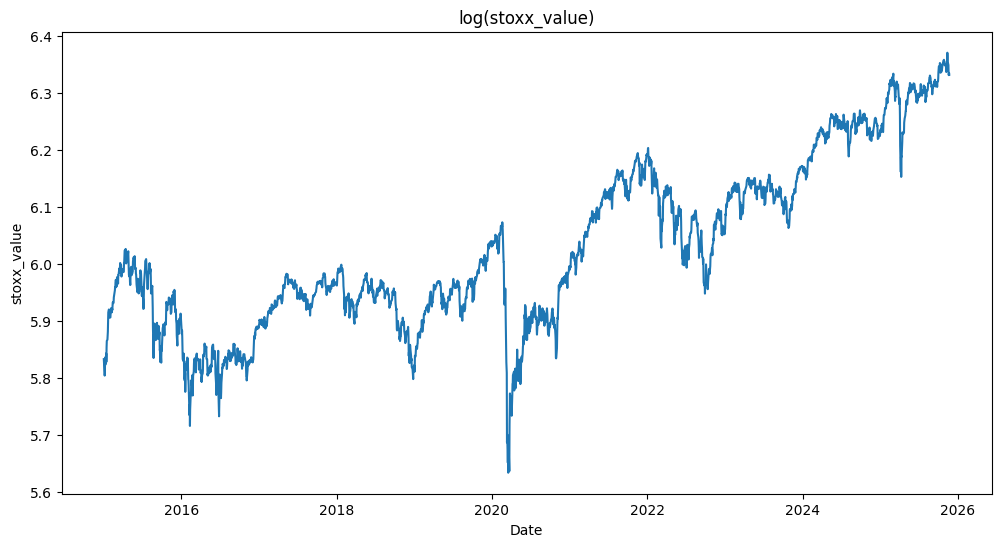

In [6]:
plot_series(data, cols, kind='line', transform='log')

### CO2 price vs other variables

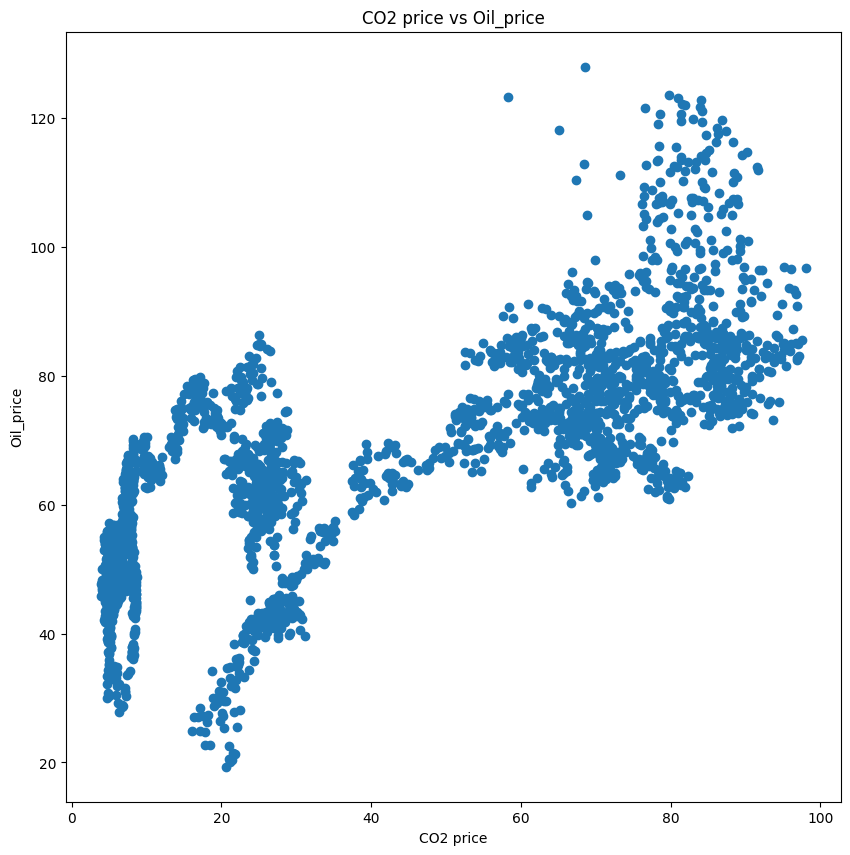

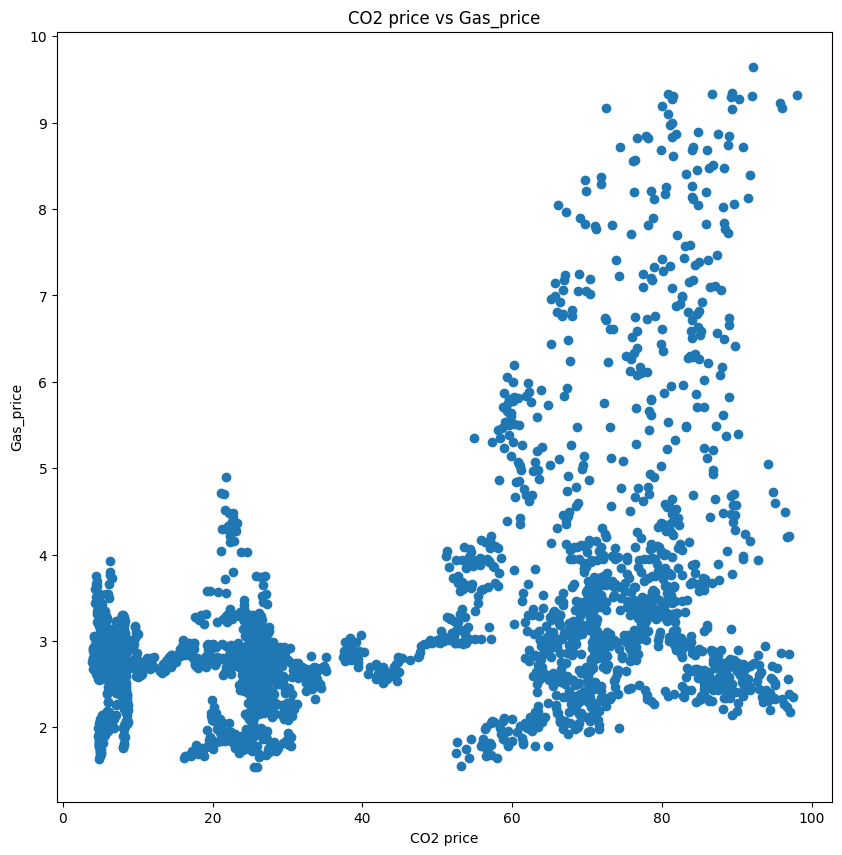

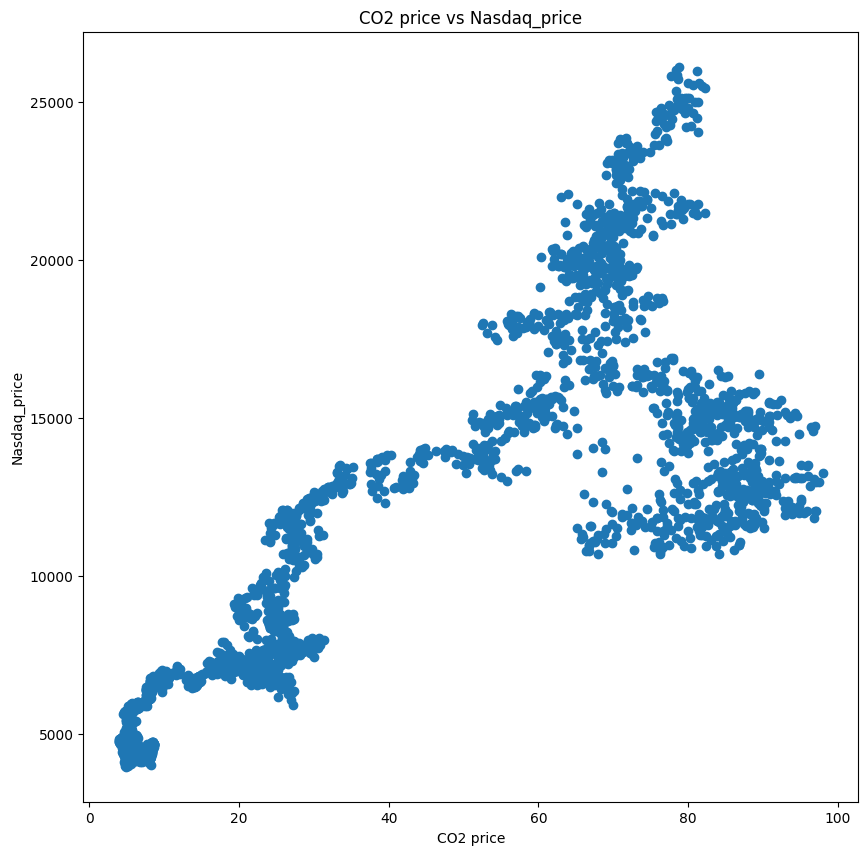

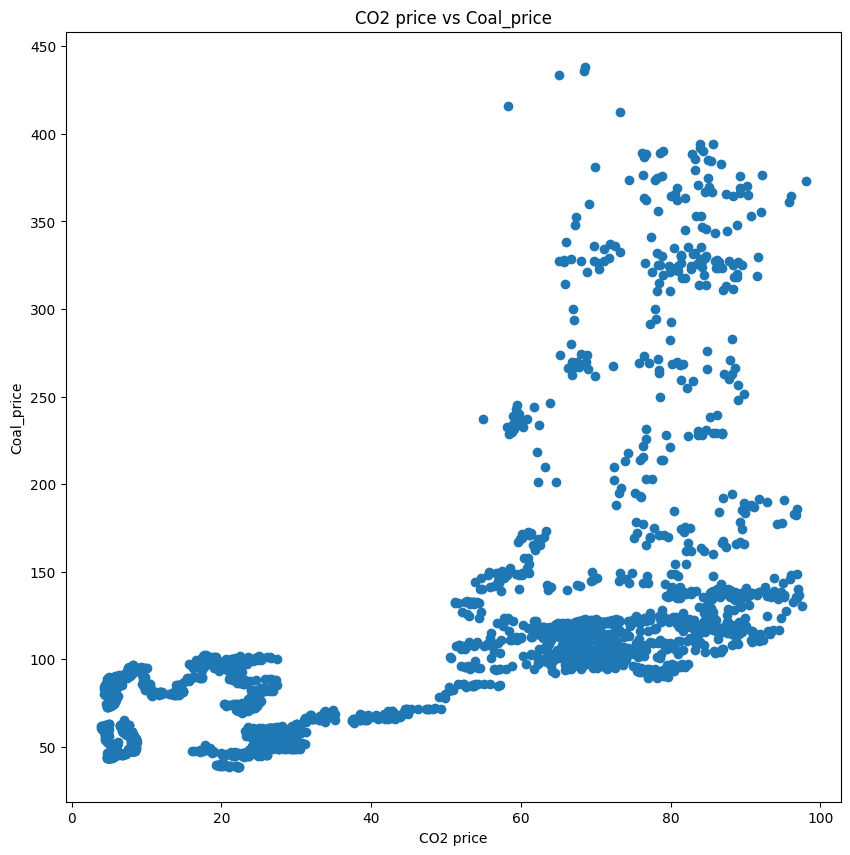

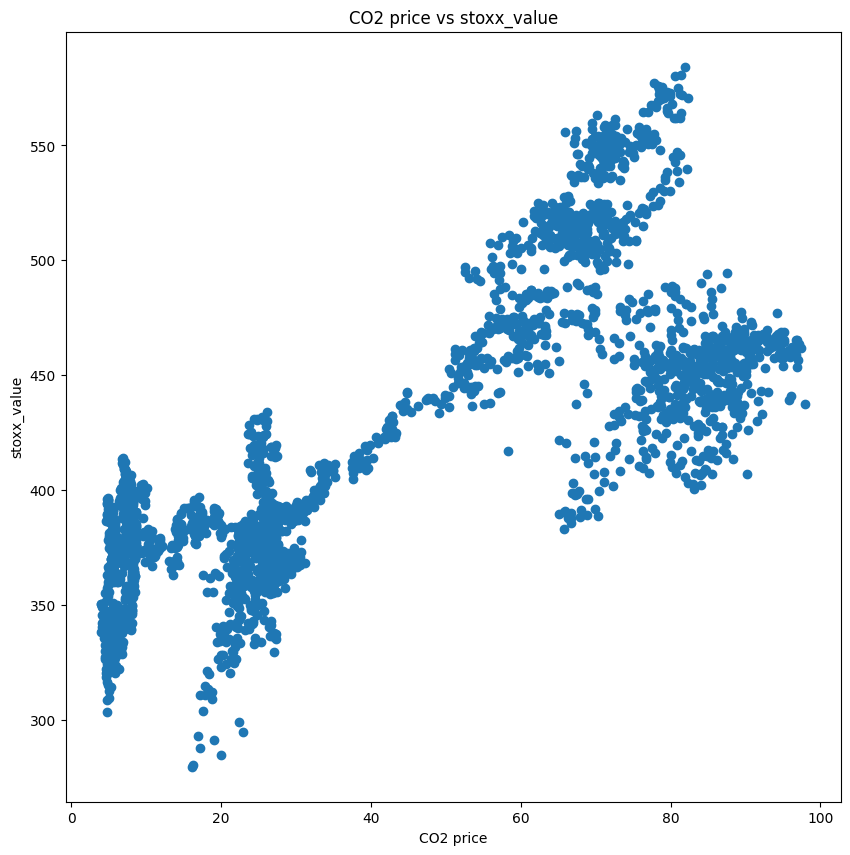

In [7]:
plot_series(data, cols, kind='scatter', transform='raw')

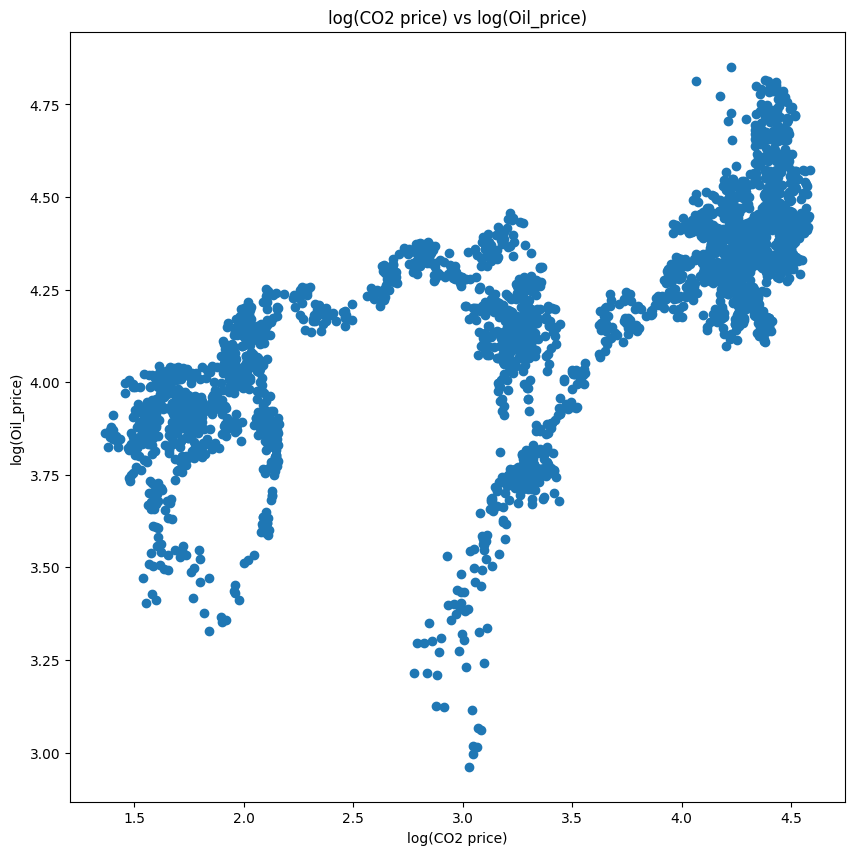

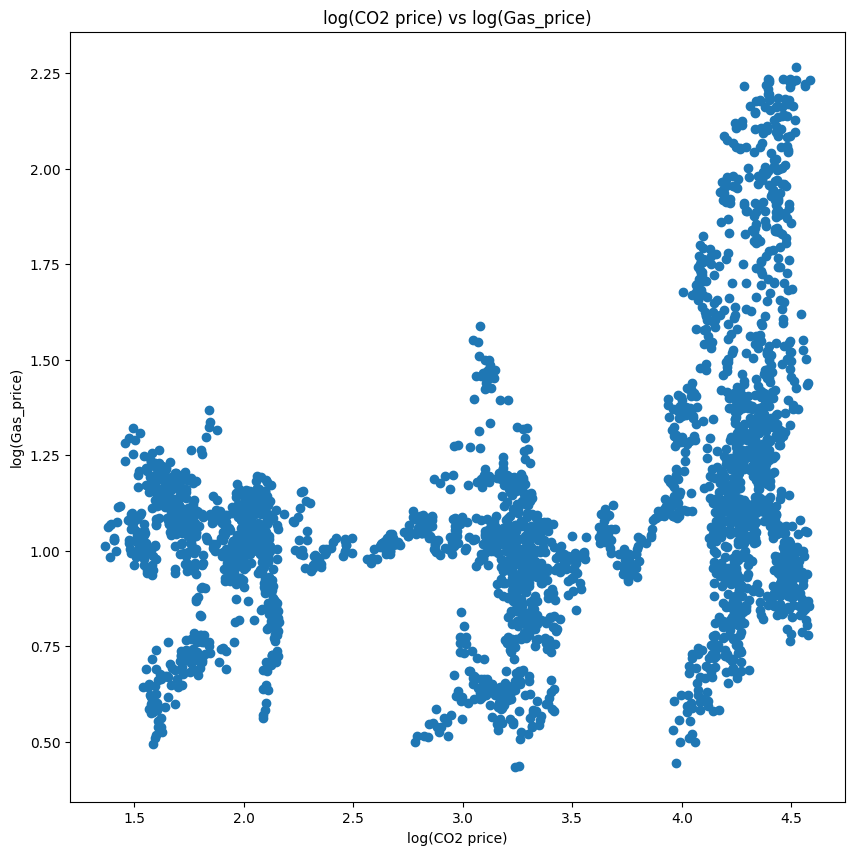

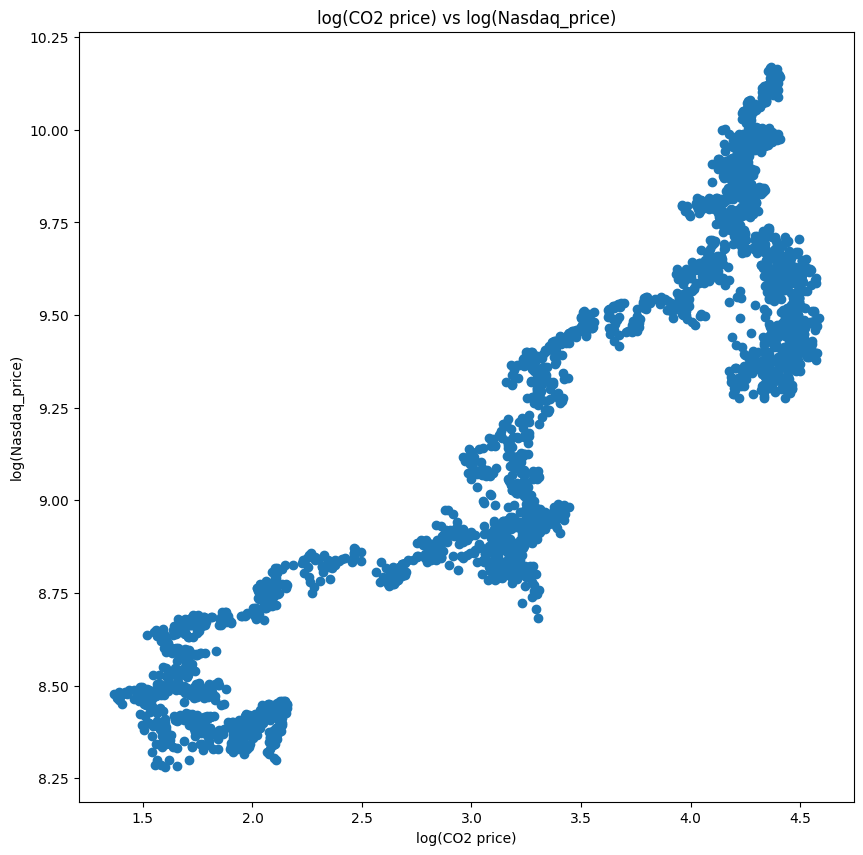

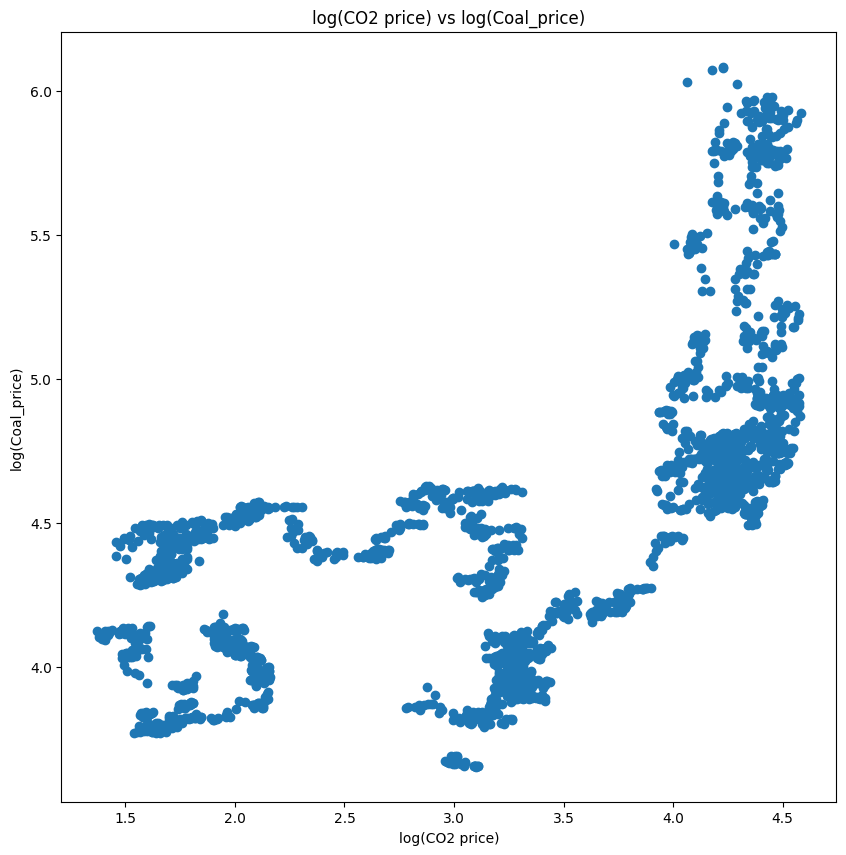

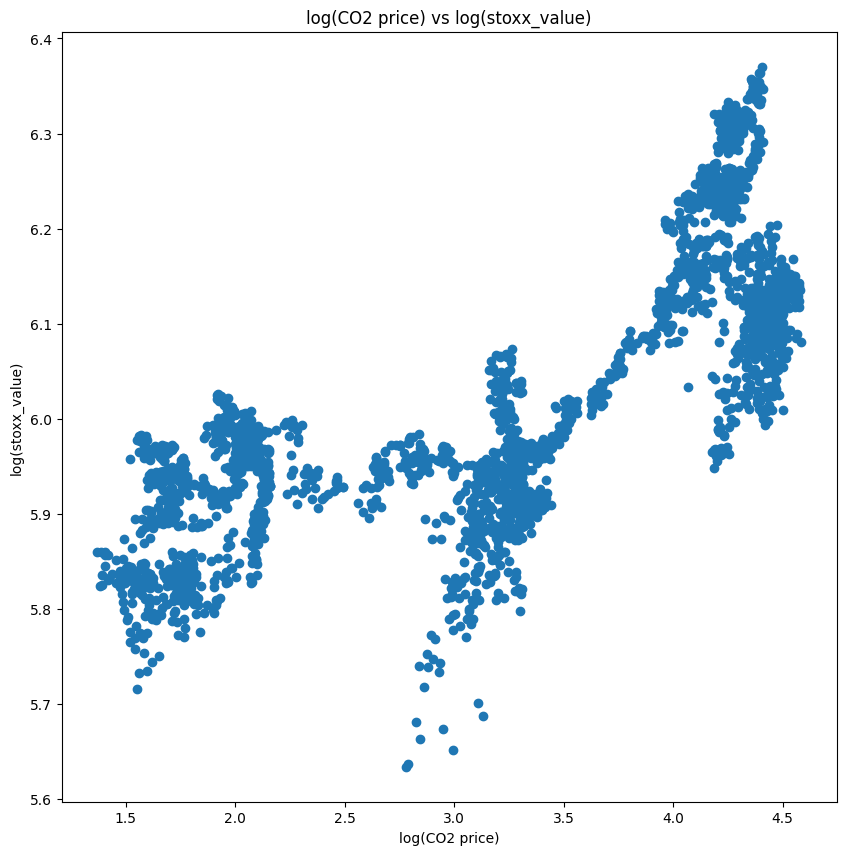

In [8]:
plot_series(data, cols, kind='scatter', transform='log')

## Statistical tests (ADF + Engle-Granger + Johansen) - one call

In [9]:
results = run_analysis(
    data,
    cols,
    target=TARGET,
    transforms=("raw", "log"),     # które wersje szeregów testować
    alpha_adf=0.01,
    alpha_coint=0.05,
    trends=("c", "ct", "ctt"),     # trendy w coint(); filtruj po kolumnie 'trend'
    n_regressors=(1, 2),           # 1 = target vs pojedyncza zmienna, 2 = target vs pary
    extra_sets=extra_sets,
    var_lags=var_lags,
    verbose=False,                 # True -> drukuje też summary() z select_order i select_coint_rank
)
adf, coint_res, johansen_res = results["adf"], results["coint"], results["johansen"]

### ADF - stationarity

In [10]:
# poziomy: które szeregi są stacjonarne
adf.query("series == 'level'")

,transform,series,variable,adf_stat,p_value,stationary
0,raw,level,target,-0.625110,0.865207,False
2,raw,level,Oil_price,-2.147551,0.225829,False
4,raw,level,Gas_price,-3.024160,0.032699,False
6,raw,level,Nasdaq_price,0.863160,0.992590,False
8,raw,level,Coal_price,-1.897003,0.333472,False
10,raw,level,stoxx_value,-0.693478,0.848432,False
12,log,level,target,-0.882636,0.793637,False
14,log,level,Oil_price,-2.346182,0.157505,False
16,log,level,Gas_price,-2.347975,0.156961,False
18,log,level,Nasdaq_price,-0.382145,0.913037,False


In [11]:
# różnice: które szeregi NIE są stacjonarne
adf.query("series == 'diff' and not stationary")

,transform,series,variable,adf_stat,p_value,stationary


In [ ]:
# zbiorczo: rząd zintegrowania każdego szeregu
integration_order(adf)

,log,raw
variable,,
Coal_price,I(1),I(1)
Gas_price,I(1),I(1)
Nasdaq_price,I(1),I(1)
Oil_price,I(1),I(1)
stoxx_value,I(1),I(1)
target,I(1),I(1)


### Engle-Granger cointegration

In [13]:
# tylko przypadki, gdzie wykryto kointegrację
coint_res.query("cointegrated").sort_values("p_value")

,transform,group,trend,regressors,p_value,cointegrated


In [14]:
# pojedyncze zmienne
coint_res.query("group == 'single'").pivot_table(
    index="regressors", columns=["transform", "trend"], values="p_value"
).round(4)

transform        log                     raw                
trend              c      ct     ctt       c      ct     ctt
regressors                                                  
Coal_price    0.8495  0.7951  0.7047  0.7495  0.1318  0.2631
Gas_price     0.7483  0.8821  0.7608  0.7172  0.4341  0.6791
Nasdaq_price  0.7484  0.9218  0.8204  0.7746  0.6846  0.8201
Oil_price     0.5834  0.6998  0.5794  0.4465  0.1905  0.3478
stoxx_value   0.3718  0.8660  0.6710  0.3018  0.8287  0.9220

In [15]:
# pary
coint_res.query("group == 'pair'").pivot_table(
    index="regressors", columns=["transform", "trend"], values="p_value"
).round(4)

transform                      log                     raw                
trend                            c      ct     ctt       c      ct     ctt
regressors                                                                
Coal_price & stoxx_value    0.6104  0.8363  0.7995  0.2319  0.3372  0.5243
Gas_price & Coal_price      0.8626  0.8965  0.8297  0.5821  0.1500  0.2505
Gas_price & Nasdaq_price    0.7371  0.9440  0.8882  0.6898  0.4630  0.6084
Gas_price & stoxx_value     0.5951  0.9183  0.8167  0.3785  0.6616  0.8185
Nasdaq_price & Coal_price   0.7918  0.9093  0.8582  0.2436  0.2515  0.3897
Nasdaq_price & stoxx_value  0.8870  0.9424  0.7971  0.8955  0.5489  0.7366
Oil_price & Coal_price      0.8809  0.8436  0.7199  0.7137  0.2392  0.3814
Oil_price & Gas_price       0.7656  0.8527  0.7409  0.6515  0.3686  0.5592
Oil_price & Nasdaq_price    0.4830  0.8168  0.7324  0.0945  0.3337  0.4490
Oil_price & stoxx_value     0.4467  0.5883  0.7261  0.1963  0.3364  0.4186

In [16]:
# zestawy: all_vars, energy_only
coint_res.query("group not in ['single', 'pair']").pivot_table(
    index=["group", "regressors"], columns=["transform", "trend"], values="p_value"
).round(4)

transform                                                          log  \
trend                                                                c   
group       regressors                                                   
all_vars    Oil_price & Gas_price & Nasdaq_price & Coal_pri...  0.7088   
energy_only Oil_price & Gas_price & Coal_price & stoxx_value    0.8673   

transform                                                               \
trend                                                               ct   
group       regressors                                                   
all_vars    Oil_price & Gas_price & Nasdaq_price & Coal_pri...  0.8313   
energy_only Oil_price & Gas_price & Coal_price & stoxx_value    0.8339   

transform                                                               \
trend                                                              ctt   
group       regressors                                                   
all_vars    Oil_price & Gas_price & Nasdaq_price & Coal_pri...  0.9323   
energy_only Oil_price & Gas_price & Coal_price & stoxx_value    0.8493   

transform                                                          raw  \
trend                                                                c   
group       regressors                                                   
all_vars    Oil_price & Gas_price & Nasdaq_price & Coal_pri...  0.3027   
energy_only Oil_price & Gas_price & Coal_price & stoxx_value    0.2703   

transform                                                                       
trend                                                               ct     ctt  
group       regressors                                                          
all_vars    Oil_price & Gas_price & Nasdaq_price & Coal_pri...  0.6101  0.7373  
energy_only Oil_price & Gas_price & Coal_price & stoxx_value    0.4322  0.5632

### Johansen test

In [17]:
johansen_res

,transform,lags,H0: rank <=,trace_stat,crit_value,reject_H0,selected_rank
0,raw,p=1 (k_ar_diff=0),0,153.986272,95.7542,True,2
1,raw,p=1 (k_ar_diff=0),1,76.818777,69.8189,True,2
2,raw,p=1 (k_ar_diff=0),2,44.766428,47.8545,False,2
3,log,p=7 (k_ar_diff=6),0,98.661057,95.7542,True,1
4,log,p=7 (k_ar_diff=6),1,54.857322,69.8189,False,1
